In [1]:
import os
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import math
import numpy as np
import pandas as pd
import seaborn as sns


import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))
from src.utils import (
    load_data
)

## ***1. Przygotowanie środowiska i danych***

In [2]:
IMAGE_PATH = '../dataset/HAM10000_images'
METADATA_PATH = '../dataset/HAM10000_metadata'

In [3]:
df = load_data(Path(METADATA_PATH))

print(f"Wymiary: ({df.shape[0]}, {df.shape[1]})")
df.head(5)

Dataset loaded.
Wymiary: (10015, 8)


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


### 1.1. Sprawdzenie rozszerzenia obrazów oraz dodanie kolumny ze ścieżką

In [4]:
files = list(Path(IMAGE_PATH).iterdir())

all_jpg = all(f.suffix.lower() == '.jpg' for f in files if f.is_file())

print(f"Wszystkie obrazy mają rozszerzenie '.jpg': {all_jpg}")

Wszystkie obrazy mają rozszerzenie '.jpg': True


In [5]:
df['Path'] = IMAGE_PATH + os.sep + df['image_id'] + ".jpg"

df.head(5)

,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,Path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern,../dataset/HAM10000_images/ISIC_0027419.jpg
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern,../dataset/HAM10000_images/ISIC_0025030.jpg
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern,../dataset/HAM10000_images/ISIC_0026769.jpg
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern,../dataset/HAM10000_images/ISIC_0025661.jpg
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern,../dataset/HAM10000_images/ISIC_0031633.jpg


### 1.2. Kontrola poprawności plików

In [6]:
valid_images = []
invalid_images = []

for path in Path(IMAGE_PATH).iterdir():
    if not path.is_file():
        continue

    try:
        with Image.open(path) as img:
            img.load()
        valid_images.append(path.name)

    except Exception:
        invalid_images.append(path.name())

print(f"Poprawne obrazy: {len(valid_images)}")
print(f"Niepoprawne obrazy: {len(invalid_images)}")

Poprawne obrazy: 10015
Niepoprawne obrazy: 0


***Wniosek:*** Wszystkie obrazy ze zbioru mają rozszerzenie ".jpg". Zostały one zweryfikowane pod względem poprawności - żaden obraz nie jest uszkodzony i można go poprawnie zdekodować. Umożliwia to dalszą analizę. Do tabeli metadanych dodano kolumnę ze ścieżką do pliku.

## ***2. Analiza wymiarów obrazów i wizualna inspekcja*** 

In [7]:
sizes = set()

for path in Path(IMAGE_PATH).iterdir():
    if not path.is_file():
        continue

    with Image.open(path) as img:
        width, height = img.size
        mode = img.mode
        channels = len(img.getbands())
        sizes.add((width, height, mode, channels))

In [8]:
sizes

{(600, 450, 'RGB', 3)}

### 2.1. Wizualizacja każdej z klas

In [9]:
samples = []
samples_per_class=5

for dx in df['dx'].unique().tolist():
    dx_samples = df[df['dx'] == dx].sample(n=samples_per_class, random_state=42)
    samples.append(dx_samples)

In [10]:
print(sum(len(samples[i]) for i in range(len(samples))))

35


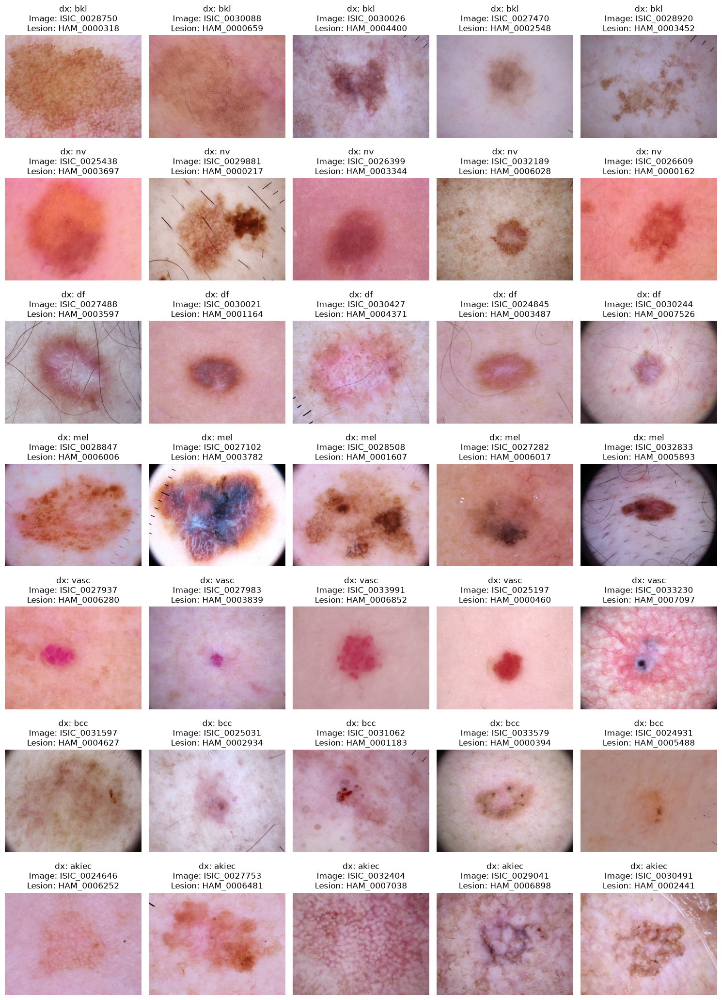

In [11]:
n_classes = len(samples)
fig, axes = plt.subplots(
    n_classes,
    samples_per_class,
    figsize=(15, 3 * n_classes)
)

row = 0

for class_samples in samples:
    col = 0

    for _, sample in class_samples.iterrows():
        ax = axes[row, col]

        with Image.open(sample['Path']) as img:
            ax.imshow(img)

        ax.set_title(
            f"dx: {sample['dx']}\n"
            f"Image: {sample['image_id']}\n"
            f"Lesion: {sample['lesion_id']}"
        )

        ax.axis('off')
        col += 1

    row += 1

plt.tight_layout()
plt.show()

### 2.2. Losowa próbka zbioru

Pobrana zostanie także losowa, większa próbka zbioru w celu zbadania obecności artefaktów.

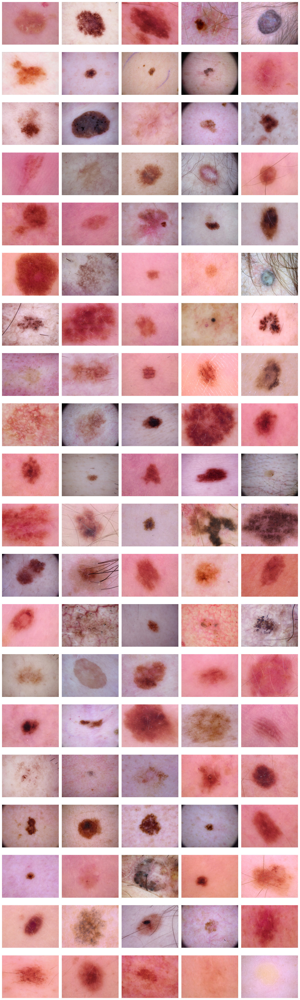

In [12]:
random_samples = df.sample(n=100, random_state=51)['Path']

fig, axes = plt.subplots(20,5, figsize=(15, 50))

row, column=0,0
for path in random_samples:
    if column!=0 and column%5==0: 
        column=0
        row+=1

    ax = axes[row, column]
    with Image.open(path) as img:
        ax.imshow(img)

    ax.axis('off')
    
    column+=1

plt.tight_layout()
plt.show()        

### Obserwacje

- Przeanalizowane obrazy dają podstawy ku stwierdzeniu, że klasy diagnostyczne są zauważalnie różne od siebie w kwestiach struktury, kształtu i kolorystyki zmiany skórnej, co czyni je rozróżnialnymi
- Wszystkie analizowane obrazy mają jednakową rozdzielczość 600 × 450 pikseli i są zapisane w przestrzeni kolorów RGB (3 kanały).
- Na analizowanych przykładach zmiany skórne są zazwyczaj dobrze widoczne i zlokalizowane centralnie.
- Pomiędzy zdjęciami, niezależnie od klasy, występuje zróżnicowanie stopnia przybliżenia, oświetlenia oraz kolorystyki skóry i samych zmian skórnych.
- Na części zdjęć występują dodatkowe artefakty obrazowania. Do najczęściej zauważalnych należą:
  - **Winietowanie** – ciemne, niekiedy czarne obszary na obrzeżach obrazu, wynikające z ograniczonego pola widzenia układu optycznego dermatoskopu.
  - **Oznaczenia skali pomiarowej** – znaczniki umożliwiające określenie wielkości zmiany skórnej.
  - **Włosy** – widoczne na powierzchni skóry, niekiedy przebiegające przez obszar zmiany.
  - **Pęcherzyki powietrza** – niewielkie struktury powstające podczas kontaktu urządzenia ze skórą.
  - **Ślady markerów** – pozostałości oznaczeń wykonanych na skórze.

**Wniosek:** Dataset charakteryzuje się spójnymi wymiarami i formatem kolorystycznym obrazów, jednak występuje w nim zróżnicowanie warunków obrazowania oraz artefakty, które należy uwzględnić podczas projektowania etapu preprocessingu.

## ***3. Analiza kolorystyczna zbioru***  

In [13]:
image_stats = []

for path in Path(IMAGE_PATH).iterdir():
    if not path.is_file():
        continue

    with Image.open(path) as img:
        grayscale = np.array(img.convert('L'))

    image_stats.append({
        'image_id': path.name[:-4],
        'brightness': grayscale.mean(),
        'contrast': grayscale.std()
    })

stats_df = pd.DataFrame(image_stats)

In [14]:
stats_df = stats_df.merge(
    df[['image_id', 'dx']],
    on='image_id',
    how='left'
)

In [15]:
stats_df

,image_id,brightness,contrast,dx
0,ISIC_0024306,146.754770,31.016334,nv
1,ISIC_0024307,152.554907,18.567454,nv
2,ISIC_0024308,153.042381,49.687620,nv
3,ISIC_0024309,134.099256,23.000077,nv
4,ISIC_0024310,153.591919,31.513469,mel
...,...,...,...,...
10010,ISIC_0034316,134.909411,32.915880,mel
10011,ISIC_0034317,203.114763,51.225645,mel
10012,ISIC_0034318,156.374685,38.893672,bkl
10013,ISIC_0034319,120.994152,24.747628,nv


### 3.1. Rozkład jasności i kontrastu obrazu

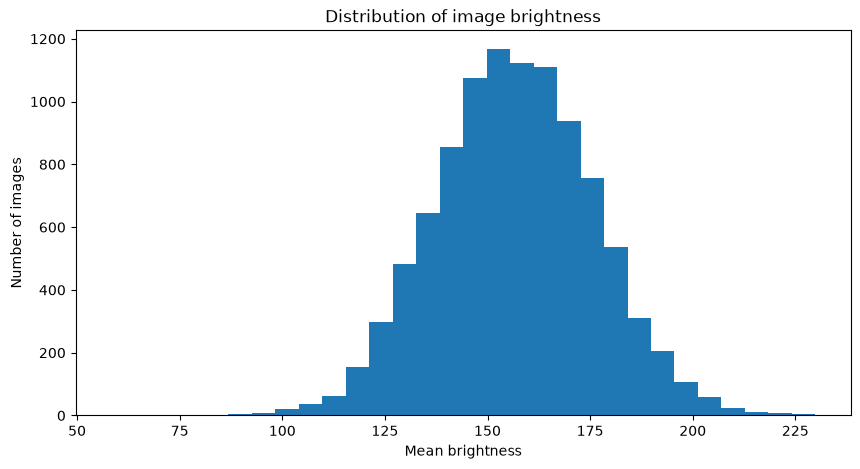

In [16]:
plt.figure(figsize=(10, 5))
plt.hist(stats_df['brightness'], bins=30)
plt.xlabel('Mean brightness')
plt.ylabel('Number of images')
plt.title('Distribution of image brightness')
plt.show()

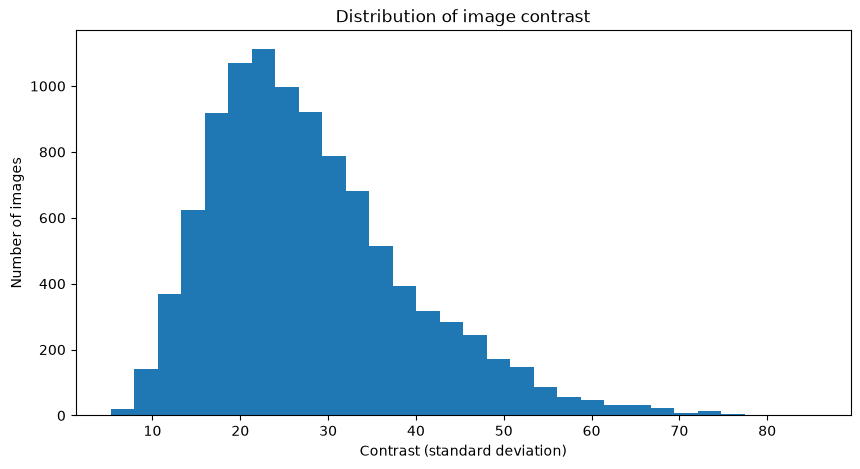

In [17]:
plt.figure(figsize=(10, 5))
plt.hist(stats_df['contrast'], bins=30)
plt.xlabel('Contrast (standard deviation)')
plt.ylabel('Number of images')
plt.title('Distribution of image contrast')
plt.show()

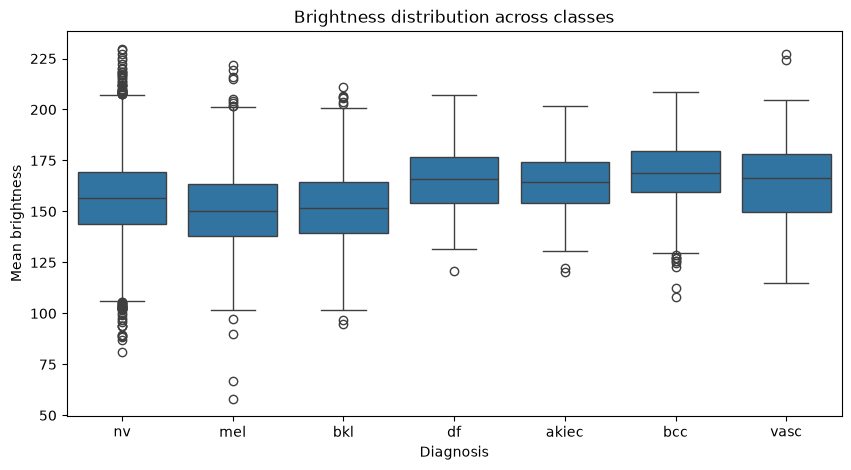

In [18]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=stats_df, x='dx', y='brightness')
plt.title('Brightness distribution across classes')
plt.xlabel('Diagnosis')
plt.ylabel('Mean brightness')
plt.show()

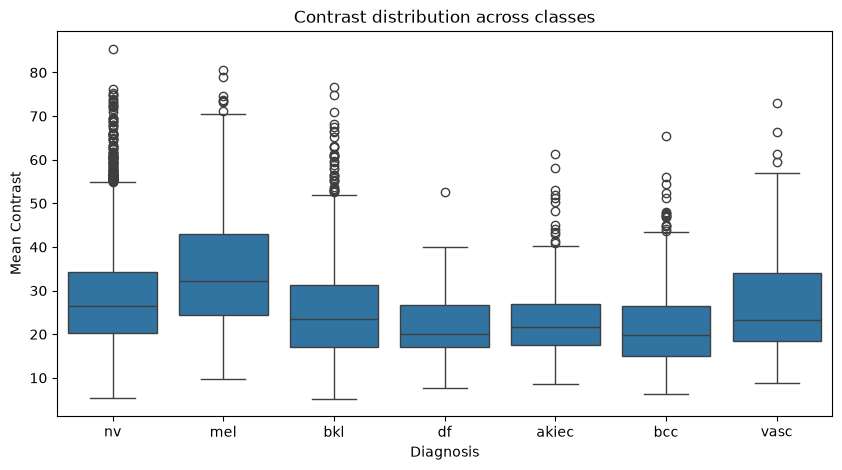

In [19]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=stats_df, x='dx', y='contrast')
plt.title('Contrast distribution across classes')
plt.xlabel('Diagnosis')
plt.ylabel('Mean Contrast')
plt.show()

***Wnioski:*** 

Rozkłady średniej jasności obrazów dla poszczególnych klas diagnostycznych wykazują pewne podobieństwa. Mediany większości klas znajdują się w przedziale około 150–170, co wskazuje na zbliżony poziom jasności analizowanych obrazów. Jednocześnie widoczne są różnice w rozrzucie wartości oraz liczbie obserwacji odstających, co świadczy o zróżnicowaniu jasności zdjęć również wewnątrz poszczególnych klas.

Najciemniejszą z klas są `mel` i `bkl`. W przypadku czerniaka (`mel`) może to wynikać z charakterystycznej, często ciemnej kolorystyki zmiany. Hipotezę tę może dodatkowo wspierać obserwowany wcześniej wysoki poziom średniego kontrastu tej klasy, wskazujący na większe różnice pomiędzy jasnością zmiany a jej otoczeniem. Z kolei stosunkowo niska jasność klasy `bkl` może być związana m.in. z powierzchnią zajmowaną przez zmianę na obrazie (zmiana `bkl` jest bardziej rozproszona, w porównaniu do czerniaka, który jest zmianą punktową), przez co jej kolorystyka może mieć większy wpływ na średnią jasność całego zdjęcia.

Średnio najjaśniejszymi klasami, także z najmniejszym rozrzutem wartości danych pod względem średniej jasności, są klasy `df`, `akiec` i `bcc`. Zbliżony poziom jasności można zaobserwować również w klasie `vasc`, jednak jej rozkład wykazuje nieco większe zróżnicowanie. Na podstawie analizowanych wcześniej zdjęć można przypuszczać, że stosunkowo wysoka jasność niektórych z tych klas jest związana z kolorystyką zmian, blendującą się z kolorytem skóry. Może to również częściowo wyjaśniać obserwowany wcześniej niższy poziom średniego kontrastu tych klas.

Warto zwrócić uwagę także na klasę `nv`, która charakteryzuje się bardzo szerokim rozrzutem danych - bardzo dużo obserwacji odstaje zarówno powyżej jak i poniżej "wąsów" na obu wykresach.

Należy jednak podkreślić, że różnice w średniej jasności pomiędzy klasami nie są bardzo duże, a rozkłady w zauważalnym stopniu się pokrywają. Sama średnia jasność obrazu prawdopodobnie nie stanowi wystarczającej cechy do jednoznacznego rozróżniania poszczególnych diagnoz, choć może być przydatną informacją.

## ***4. Analiza rozkładu kolorów***

In [20]:
image_color_stats = []

for path in Path(IMAGE_PATH).iterdir():
    if not path.is_file():
        continue

    with Image.open(path) as img:
            img = np.array(img)
            mean_R = np.mean(img[:,:,0])
            mean_G = np.mean(img[:,:,1])
            mean_B = np.mean(img[:,:,2])
    image_color_stats.append({'image_id': path.name[:-4], 'R': mean_R, 'G': mean_G, 'B': mean_B})

color_stats_df = pd.DataFrame(image_color_stats)

In [21]:
color_stats_df = color_stats_df.merge(
    df[['image_id', 'dx']],
    on='image_id',
    how='left'
)

In [22]:
color_stats_df.head(10)

,image_id,R,G,B,dx
0,ISIC_0024306,214.742830,117.623078,118.454056,nv
1,ISIC_0024307,216.408637,124.305130,130.559900,nv
2,ISIC_0024308,211.505348,128.136615,127.854930,nv
3,ISIC_0024309,193.472681,107.059463,117.562107,nv
4,ISIC_0024310,201.125259,133.741378,130.974178,mel
5,ISIC_0024311,228.554230,137.755956,143.146589,nv
6,ISIC_0024312,193.221044,149.785111,177.563481,bkl
7,ISIC_0024313,217.396993,181.887130,196.297796,mel
8,ISIC_0024314,186.978974,163.454793,188.659030,nv
9,ISIC_0024315,159.495452,132.265715,153.721004,mel


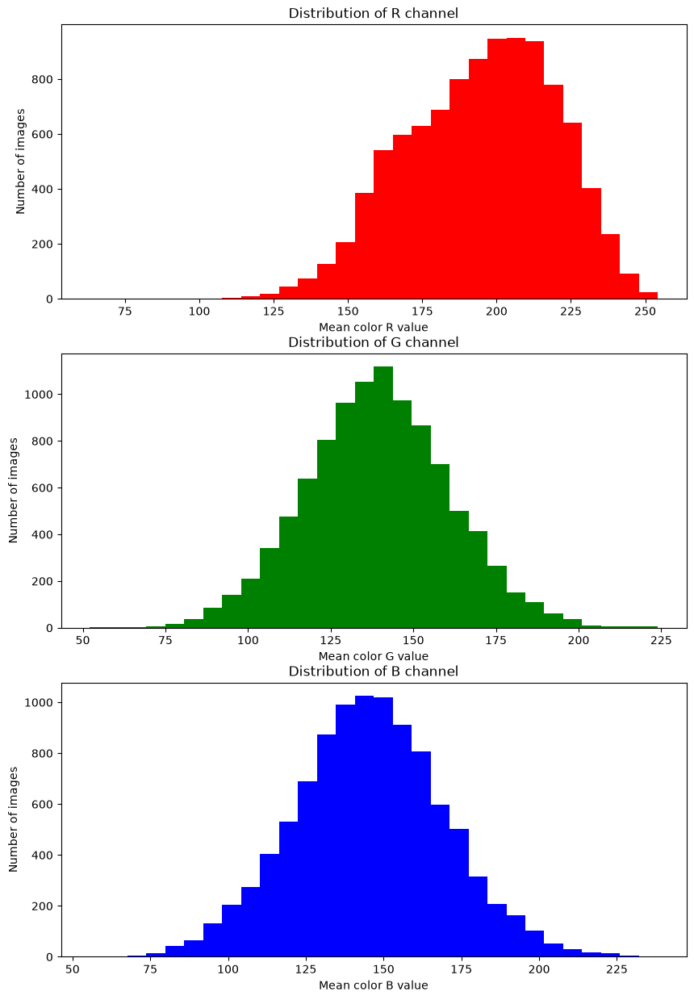

In [23]:
plt.figure(figsize=(10, 15))
plt.subplot(3,1,1)
plt.hist(color_stats_df['R'], bins=30, color='r')
plt.xlabel('Mean color R value')
plt.ylabel('Number of images')
plt.title('Distribution of R channel')

plt.subplot(3,1,2)
plt.hist(color_stats_df['G'], bins=30, color='g')
plt.xlabel('Mean color G value')
plt.ylabel('Number of images')
plt.title('Distribution of G channel')

plt.subplot(3,1,3)
plt.hist(color_stats_df['B'], bins=30, color='b')
plt.xlabel('Mean color B value')
plt.ylabel('Number of images')
plt.title('Distribution of B channel')
plt.show()

Analiza histogramów kanałów RGB wskazuję na dominację kanału R. Rozkłady kanałów GB skupiają się wokół wartości odpowiednio $130$ i $145$ i przypominają rozkład normalny. Kanał R charakteryzuje się zaś przesunięciem w stronę wyższych wartości, gdzie dominują wartości z przedziału $180-220$. Wskazuje to na przewagę ciepłych odcieni w analizowanym zbiorze, co może wynikać zarówno z naturalnej kolorystyki skóry jak i charakterystyki przedstawionych zmian skórnych. Należy więc przeanalizować te wartości z podziałem na klasy

In [24]:
color_stats_df.groupby('dx')[['R', 'G', 'B']].agg(
    ['mean', 'median', 'std']
)

R                                  G                         \
             mean      median        std        mean      median        std   
dx                                                                            
akiec  198.402547  198.998467  16.938745  149.135171  148.807593  16.366975   
bcc    195.264146  196.010907  17.985843  155.760707  156.053165  17.896531   
bkl    178.191548  176.242785  22.278560  139.449401  139.264026  18.081691   
df     198.781621  201.813663  20.778851  150.931719  151.557322  16.998184   
mel    177.836175  177.012615  21.805604  137.950207  137.231352  19.661501   
nv     199.829921  203.389367  24.586690  137.300231  137.284622  22.570876   
vasc   198.397481  196.907663  19.237599  148.861650  151.905919  22.035002   

                B                         
             mean      median        std  
dx                                        
akiec  154.721517  153.085570  17.992843  
bcc    162.419955  163.028463  20.461459  
bkl    147.209999  147.100356  19.017058  
df     159.224395  159.677281  20.413973  
mel    144.895852  144.511330  21.179477  
nv     142.960617  142.782448  25.213354  
vasc   162.270566  163.059070  23.128885

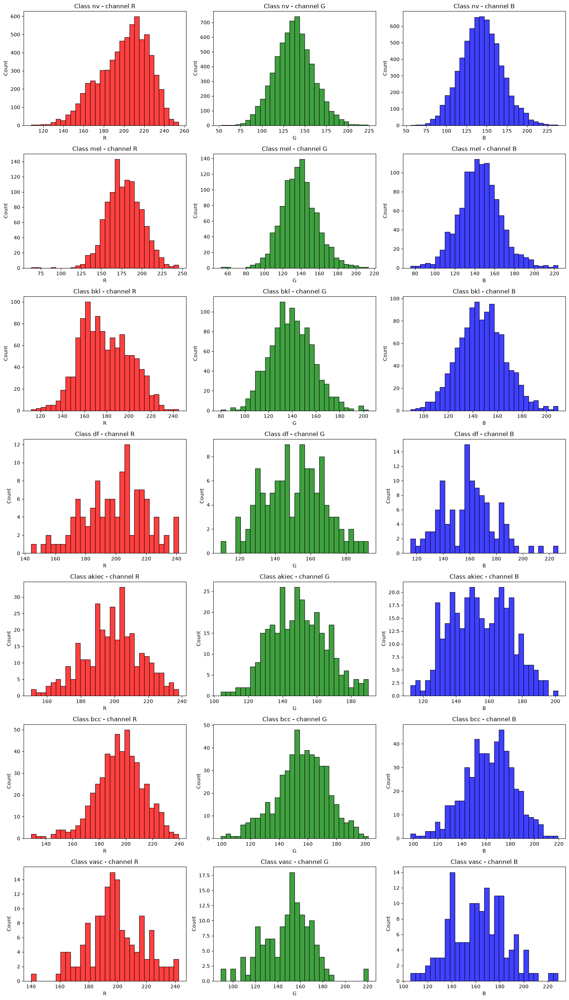

In [25]:
channels = ['R', 'G', 'B']
classes = color_stats_df['dx'].unique()

fig, axes = plt.subplots(
    len(classes), 3,
    figsize=(16, 4 * len(classes))
)

for i, class_name in enumerate(classes):
    class_data = color_stats_df[
        color_stats_df['dx'] == class_name
    ]

    for j, channel in enumerate(channels):
        sns.histplot(
            data=class_data,
            x=channel,
            bins=30,
            ax=axes[i, j],
            color=channels[j].lower()
        )

        axes[i, j].set_title(
            f'Class {class_name} - channel {channel}'
        )

plt.tight_layout()
plt.show()

***Wnioski***

Analiza histogramów kanałów RGB wykazała wyraźną przewagę intensywności kanału czerwonego (R) nad kanałami zielonym (G) i niebieskim (B). Może to wskazywać na dominację ciepłych odcieni w analizowanym zbiorze obrazów, co prawdopodobnie wynika w dużej mierze z naturalnej kolorystyki skóry widocznej na zdjęciach.

Porównanie histogramów poszczególnych klas diagnostycznych nie wykazało wyraźnych różnic w rozkładach wartości kanałów RGB. W przypadku liczniejszych klas można zaobserwować niewielkie przesunięcia rozkładów lub różnice w ich szerokości, jednak nie są one na tyle wyraźne, aby pozwalały na jednoznaczne rozróżnienie poszczególnych klas na podstawie analizowanych cech. W klasach o mniejszej liczbie obserwacji histogramy charakteryzują się większą nieregularnością, co utrudnia ich interpretację.

Uzyskane wyniki sugerują, że średnie wartości kanałów RGB nie stanowią samodzielnie wystarczająco charakterystycznych cech do rozróżniania analizowanych diagnoz. Dominacja kanału czerwonego wydaje się natomiast cechą wspólną dla całego zbioru, a nie właściwością charakterystyczną dla konkretnej klasy diagnostycznej.



## ***5. Analiza wielu obrazów tej samej zmiany skórnej***

Liczba unikalnych zmian posiadających wiele zdjęć: 1956

Analiza zmiany 1: Lesion ID: HAM_0003789 | Diagnoza (dx): bkl | Liczba ujęć: 6


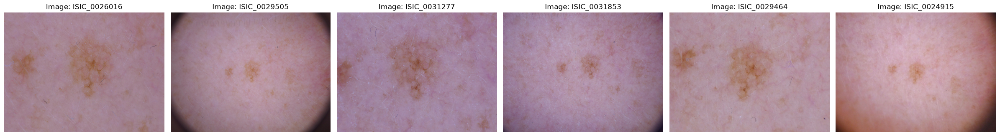


Analiza zmiany 2: Lesion ID: HAM_0000835 | Diagnoza (dx): bkl | Liczba ujęć: 6


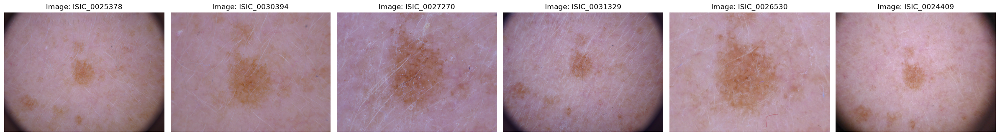


Analiza zmiany 3: Lesion ID: HAM_0001863 | Diagnoza (dx): mel | Liczba ujęć: 6


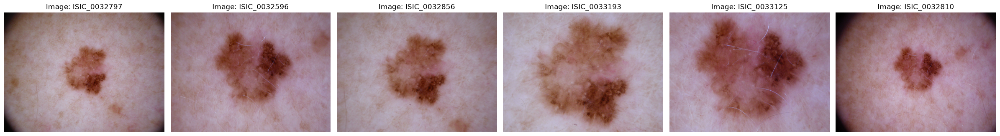


Analiza zmiany 4: Lesion ID: HAM_0005263 | Diagnoza (dx): nv | Liczba ujęć: 6


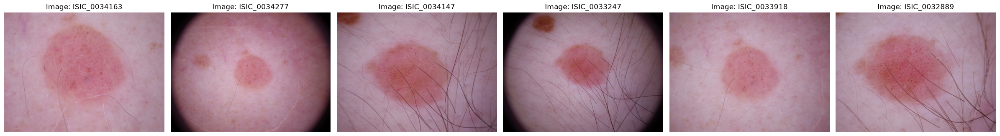


Analiza zmiany 5: Lesion ID: HAM_0000893 | Diagnoza (dx): bkl | Liczba ujęć: 5


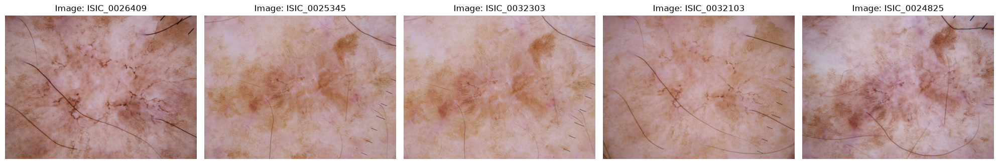

In [26]:
lesion_counts = df['lesion_id'].value_counts()
multiple_images_lesions = lesion_counts[lesion_counts > 1].index.tolist()
print(f"Liczba unikalnych zmian posiadających wiele zdjęć: {len(multiple_images_lesions)}")

num_samples_to_show = 5

for i in range(num_samples_to_show):
    sample_lesion_id = multiple_images_lesions[i]
    sample_rows = df[df['lesion_id'] == sample_lesion_id]
    
    sample_path = df[df['lesion_id'] == sample_lesion_id]['Path'].tolist()
    image_ids = sample_rows['image_id'].tolist()
    dx_label = sample_rows['dx'].iloc[0]
    
    print(f"\nAnaliza zmiany {i+1}: Lesion ID: {sample_lesion_id} | Diagnoza (dx): {dx_label} | Liczba ujęć: {len(image_ids)}")
    fig, axes = plt.subplots(1, len(image_ids), figsize=(4 * len(image_ids), 4))
        
    for ax, img_id, path in zip(axes, image_ids, sample_path):
        with Image.open(path) as img:
            ax.imshow(img)
            ax.set_title(f"Image: {img_id}")
            ax.axis('off')
            
    plt.tight_layout()
    plt.show()

***Wnioski***

Analiza zdjęć zmian skórnych o wielu reprezentacjach pozwala zauważyć dla poszczególnych ujęć następujące różnice:
- Kadrowanie i skala: Zdjęcia wykonane są z różnej odległości. Niektóre z reprezentacji pokazują zmianę w dużym przybliżeniu, tak, że zajmuje niemal cały kadr, podczas gdy inne pokazują ją z większej perspektywy.
- Oświetlenie: Widoczne są wahania jasności oraz inne odbicia światła, co wpływa na kontrast i barwę zmiany.
- Kąt nachylenia i perspektywa: Zdjęcia są robione pod różnym kątem.
- Obecność i widoczność artefaktów: Niektóre z reprezentacji zawierają artefakty, podczas gdy na innych znajdują się ona poza obrębem zmiany skórnej, lub ich nie ma.

## ***6. Wnioski z eksploracyjnej analizy danych - obrazów***

- ***Zweryfikowano kompletność zbioru i poprawność plików:*** Zbiór obejmuje $10015$ poprawnych plików, wszyskie w formacie '.jpg'. Każdy obraz ma identyczną rozdzielczość $600x450$ pikseli oraz zapis w przestrzeni barw RGB. Eliminuje to konieczność ujednolicania formatów lub proporcji obrazu.

- ***Jakość obrazów, widoczność zmian:*** Na podstawie przeanalizowanych próbek można stwierdzić, że zmiany skórne są w większości dobrze wyeksponowane i wycentrowane. Na zdjęciach jednak występują artefakty takie jak: ***owłosienie***, ***znaczniki skali pomiarowej***, ***pęcherzyki powietrza***, ***ślady markerów na skórze***, ***czarne narożniki wynikające z działania dermatoskopu***.

- ***Charakterystyka jasności i kontrastu:*** Rozkład średniej jasności w całym zbiorze jest zbliżony do normalnego (mediany dla poszczególnych klas mieszczą się w przedziale ok. $150–170$), natomiast rozkład kontrastu jest prawostronnie skośny. Najniższą jasnością i najwyższym kontrastem wyróżnia się klasa `mel` (czerniak – ciemna zmiana wyraźnie odcinająca się od otoczenia) oraz `bkl` (często rozległe, ciemniejsze zmiany). Z kolei klasy `df`, `akiec` oraz `bcc` są średnio najjaśniejsze i wykazują niższy kontrast ze względu na barwę zbliżoną do odcienia zdrowej skóry. Klasa `nv` cechuje się największą liczbą obserwacji odstających pod względem obu metryk.

- ***Dominacja kanału czerwonego (RGB):*** W zbiorze wyraźnie przeważa kanał czerwony *R*, nad kanałami zielonym *G* oraz niebieskim *B*, co związane jest z kolorytem ludzkiej skóry, będącej obiektem zdjęć. Rozkłady średnich wartości RGB, jasności i kontrastu w dużym stopniu nakładają się między diagnozami – proste, globalne statystyki pikseli nie wystarczą do jednoznacznej separacji klas.

- ***Obecność wielokrotnych ujęć tej samej zmiany:*** W zbiorze zidentyfikowano $1956$ unikalnych zmian skórnych, które posiadają więcej niż jedną reprezentację. Niektóre zmiany skórne w zbiorze mają nawet 6 ujęć. Poszczególne fotografie różnią się skalą, kątem nachylenia, oświetleniem i obecnością/ułożeniem artefaktów